In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

import joblib
import os

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.20.0
NumPy version: 2.0.2
Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("File:", filename)
print("Shape:", df.shape)

Saving dataset.csv to dataset (3).csv
Dataset loaded successfully!
File: dataset (3).csv
Shape: (197428, 14)


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (197428, 14)

Column Names:
['market_id', 'created_at', 'actual_delivery_time', 'store_id', 'store_primary_category', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_partners', 'total_busy_partners', 'total_outstanding_orders']

First 5 Rows:


,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_partners,total_busy_partners,total_outstanding_orders
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,df263d996281d984952c07998dc54358,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,f0ade77b43923b38237db569b016ba25,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,f0ade77b43923b38237db569b016ba25,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,f0ade77b43923b38237db569b016ba25,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,f0ade77b43923b38237db569b016ba25,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0



Data Types:
market_id                   float64
created_at                   object
actual_delivery_time         object
store_id                     object
store_primary_category       object
order_protocol              float64
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_partners      float64
total_busy_partners         float64
total_outstanding_orders    float64
dtype: object


In [5]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Cleaned columns:")
print(df.columns.tolist())

Cleaned columns:
['market_id', 'created_at', 'actual_delivery_time', 'store_id', 'store_primary_category', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_partners', 'total_busy_partners', 'total_outstanding_orders']


In [6]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df)) * 100
})

display(
    missing_table.sort_values(
        "Missing Values",
        ascending=False
    )
)

,Missing Values,Percentage
total_outstanding_orders,16262,8.236927
total_busy_partners,16262,8.236927
total_onshift_partners,16262,8.236927
store_primary_category,4760,2.411006
order_protocol,995,0.503981
market_id,987,0.499929
actual_delivery_time,7,0.003546
created_at,0,0.000000
store_id,0,0.000000
total_items,0,0.000000


In [7]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")

print("New dataset shape:", df.shape)

Duplicate rows: 0
New dataset shape: (197428, 14)


In [8]:
df["created_at"] = pd.to_datetime(
    df["created_at"],
    errors="coerce"
)

df["actual_delivery_time"] = pd.to_datetime(
    df["actual_delivery_time"],
    errors="coerce"
)

print(df[[
    "created_at",
    "actual_delivery_time"
]].head())

print("\nMissing timestamps:")
print(
    df[[
        "created_at",
        "actual_delivery_time"
    ]].isnull().sum()
)

           created_at actual_delivery_time
0 2015-02-06 22:24:17  2015-02-06 23:27:16
1 2015-02-10 21:49:25  2015-02-10 22:56:29
2 2015-01-22 20:39:28  2015-01-22 21:09:09
3 2015-02-03 21:21:45  2015-02-03 22:13:00
4 2015-02-15 02:40:36  2015-02-15 03:20:26

Missing timestamps:
created_at              0
actual_delivery_time    7
dtype: int64


In [9]:
df["delivery_time_minutes"] = (
    df["actual_delivery_time"]
    - df["created_at"]
).dt.total_seconds() / 60

print(
    df["delivery_time_minutes"].describe()
)

count    197421.000000
mean         48.470956
std         320.493482
min           1.683333
25%          35.066667
50%          44.333333
75%          56.350000
max      141947.650000
Name: delivery_time_minutes, dtype: float64


In [10]:
before = len(df)

df = df[
    (df["delivery_time_minutes"] > 0) &
    (df["delivery_time_minutes"] < 300)
].copy()

after = len(df)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

Rows before: 197428
Rows after: 197386
Rows removed: 42


In [11]:
df["order_hour"] = df["created_at"].dt.hour
df["order_day"] = df["created_at"].dt.day
df["order_month"] = df["created_at"].dt.month
df["day_of_week"] = df["created_at"].dt.dayofweek

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

print(df[[
    "order_hour",
    "order_day",
    "order_month",
    "day_of_week",
    "is_weekend"
]].head())

   order_hour  order_day  order_month  day_of_week  is_weekend
0          22          6            2            4           0
1          21         10            2            1           0
2          20         22            1            3           0
3          21          3            2            1           0
4           2         15            2            6           1


In [12]:
required_columns = [
    "market_id",
    "store_id",
    "store_primary_category",
    "order_protocol",
    "total_items",
    "num_distinct_items",
    "min_item_price",
    "max_item_price",
    "total_onshift_partners",
    "total_busy_partners",
    "total_outstanding_orders"
]

print("Checking required columns...\n")

for col in required_columns:
    if col in df.columns:
        print("✓", col)
    else:
        print("✗ MISSING:", col)

Checking required columns...

✓ market_id
✓ store_id
✓ store_primary_category
✓ order_protocol
✓ total_items
✓ num_distinct_items
✓ min_item_price
✓ max_item_price
✓ total_onshift_partners
✓ total_busy_partners
✓ total_outstanding_orders


In [13]:
features = [
    "market_id",
    "store_id",
    "store_primary_category",
    "order_protocol",
    "total_items",
    "num_distinct_items",
    "min_item_price",
    "max_item_price",
    "total_onshift_partners",
    "total_busy_partners",
    "total_outstanding_orders",
    "order_hour",
    "order_day",
    "order_month",
    "day_of_week",
    "is_weekend"
]

target = "delivery_time_minutes"

X = df[features].copy()
y = df[target].copy()

print("Number of features:", len(features))
print("\nFeatures:")
print(features)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Number of features: 16

Features:
['market_id', 'store_id', 'store_primary_category', 'order_protocol', 'total_items', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_partners', 'total_busy_partners', 'total_outstanding_orders', 'order_hour', 'order_day', 'order_month', 'day_of_week', 'is_weekend']

X shape: (197386, 16)
y shape: (197386,)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 157908
Testing rows: 39478


In [26]:
store_frequency = X_train["store_id"].value_counts(normalize=True)

X_train["store_frequency"] = (
    X_train["store_id"]
    .map(store_frequency)
    .fillna(0)
)

X_test["store_frequency"] = (
    X_test["store_id"]
    .map(store_frequency)
    .fillna(0)
)
X_train = X_train.drop(columns=["store_id"])
X_test = X_test.drop(columns=["store_id"])

print("Store ID converted to frequency.")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Store ID converted to frequency.
Training shape: (157908, 16)
Testing shape: (39478, 16)


In [27]:
categorical_features = [
    "store_primary_category"
]

numerical_features = [
    "market_id",
    "order_protocol",
    "total_items",
    "num_distinct_items",
    "min_item_price",
    "max_item_price",
    "total_onshift_partners",
    "total_busy_partners",
    "total_outstanding_orders",
    "order_hour",
    "order_day",
    "order_month",
    "day_of_week",
    "is_weekend",
    "store_frequency"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['store_primary_category']

Numerical features:
['market_id', 'order_protocol', 'total_items', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_partners', 'total_busy_partners', 'total_outstanding_orders', 'order_hour', 'order_day', 'order_month', 'day_of_week', 'is_weekend', 'store_frequency']


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Processed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)

print("NaN values in training:",
      np.isnan(X_train_processed).sum())

print("NaN values in testing:",
      np.isnan(X_test_processed).sum())

Preprocessing completed!
Processed training shape: (157908, 89)
Processed testing shape: (39478, 89)
NaN values in training: 0
NaN values in testing: 0


In [29]:
X_train_processed = np.asarray(
    X_train_processed,
    dtype="float32"
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype="float32"
)

y_train = np.asarray(
    y_train,
    dtype="float32"
)

y_test = np.asarray(
    y_test,
    dtype="float32"
)

print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nNaN check:")
print("X_train NaN:", np.isnan(X_train_processed).sum())
print("X_test NaN:", np.isnan(X_test_processed).sum())
print("y_train NaN:", np.isnan(y_train).sum())
print("y_test NaN:", np.isnan(y_test).sum())

X_train: (157908, 89)
X_test: (39478, 89)
y_train: (157908,)
y_test: (39478,)

NaN check:
X_train NaN: 0
X_test NaN: 0
y_train NaN: 0
y_test NaN: 0


In [30]:
input_features = X_train_processed.shape[1]

model = Sequential([
    Input(shape=(input_features,)),

    Dense(128, activation="relu"),
    Dropout(0.20),

    Dense(64, activation="relu"),
    Dropout(0.20),

    Dense(32, activation="relu"),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │        11,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,889 (85.50 KB)

 Trainable params: 21,889 (85.50 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

print("Training completed!")

Epoch 1/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 350.3030 - mae: 13.5024 - val_loss: 281.3379 - val_mae: 11.9471
Epoch 2/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 291.8736 - mae: 12.4352 - val_loss: 271.1477 - val_mae: 11.9317
Epoch 3/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 285.5369 - mae: 12.2888 - val_loss: 268.5710 - val_mae: 11.8734
Epoch 4/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 281.2684 - mae: 12.1831 - val_loss: 272.5730 - val_mae: 11.6530
Epoch 5/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 277.7635 - mae: 12.1059 - val_loss: 270.2826 - val_mae: 11.6404
Epoch 6/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 275.9641 - mae: 12.0609 - val_loss: 267.4344 - val_mae: 11.6442
Epoch 7/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 272.4767 - mae: 11.9956 - val_loss: 266.4748 - val_mae: 11.6514
Epoch 8/100
1974/1974 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 270.8736 - mae: 11.9500 - val_loss: 263.9799 - 

In [32]:
y_pred = model.predict(
    X_test_processed,
    verbose=0
).flatten()

print("NaN predictions:", np.isnan(y_pred).sum())

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_test[:10])

NaN predictions: 0

First 10 predictions:
[39.631123 32.15562  43.187702 44.49841  42.048298 42.441486 42.93212
 45.211166 49.370625 41.44666 ]

First 10 actual values:
[48.316666 27.283333 45.2      37.866665 48.783333 36.366665 54.45
 41.783333 53.583332 51.866665]


In [33]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("===================================")
print("       MODEL PERFORMANCE")
print("===================================")

print(f"MAE  : {mae:.2f} minutes")
print(f"RMSE : {rmse:.2f} minutes")
print(f"R²   : {r2:.4f}")

       MODEL PERFORMANCE
MAE  : 11.51 minutes
RMSE : 16.14 minutes
R²   : 0.2285


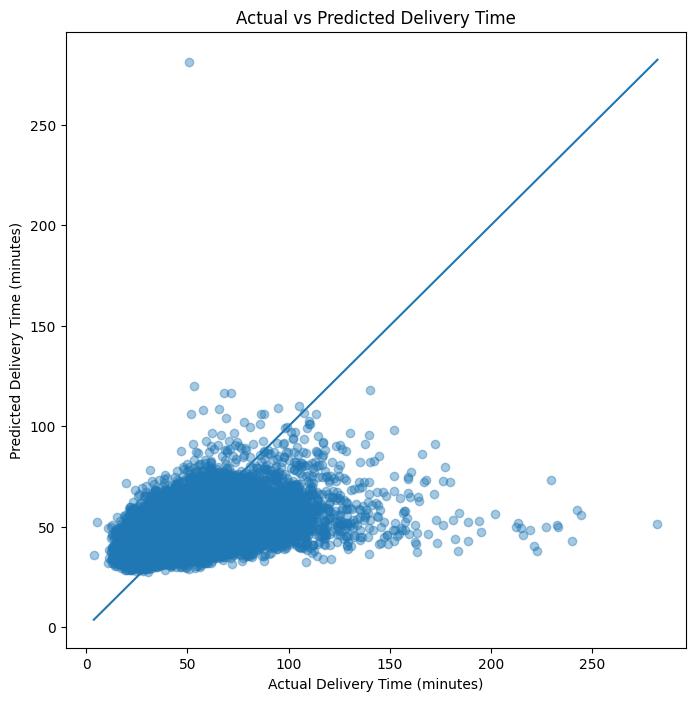

In [34]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

min_value = min(
    y_test.min(),
    y_pred.min()
)

max_value = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value]
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")

plt.show()